# 02 · Loot boxes: odds, expected value and the gambler's fallacy

Every loot box in Crawl Live! shows its drop table before you open it. This notebook checks those odds against what 2,000 bot runs actually received, then uses the boxes to work through some core probability ideas, building up one step at a time:

1. **Probability distribution:** the list of outcomes and how likely each is.
2. **Expected value (EV):** the long-run average, $E[X] = \sum_i p_i x_i$.
3. **Standard deviation (SD):** how far a single result typically lands from the average.
4. **Hypothesis testing:** do the boxes really pay out at the stated odds?
5. **Independence:** why a run of bad luck doesn't make good luck "due".

In [1]:
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from common import MUTED, SEQUENTIAL, SERIES, TEXT_2, load, pct_axis, style, value_grid
from crawler.items import ITEMS
from crawler.loot import (BOX_TIERS, TIERS, TRADE_UP_COST, box_stats, next_tier, odds,
                          reroll_fee, roll_box)

style()
boxes = load("boxes")
print(f"{len(boxes):,} boxes opened across {boxes['run_id'].nunique():,} runs")
boxes["tier"].value_counts().reindex(TIERS).rename("boxes opened").to_frame().T

27,084 boxes opened across 1,931 runs


tier,bronze,silver,gold,platinum,legendary
boxes opened,8245,10224,6365,1490,760


## 1. The stated distributions

Each tier is a weighted table of four items. Item value is the shop price in gold, so we can talk about what a box is *worth*.

In [2]:
rows = []
for tier in TIERS:
    ev, sd = box_stats(tier)
    for key, p in odds(tier):
        rows.append(dict(tier=BOX_TIERS[tier]["name"], item=ITEMS[key]["name"], chance=p,
                         value=ITEMS[key]["value"], tier_ev=ev, tier_sd=sd))
table = pd.DataFrame(rows)
table.style.format({"chance": "{:.0%}", "tier_ev": "{:.1f}", "tier_sd": "{:.1f}"}).hide(axis="index")

tier,item,chance,value,tier_ev,tier_sd
Bronze,Soggy Sock,29%,2,7.1,3.4
Bronze,Fizzy Tonic,29%,8,7.1,3.4
Bronze,Party Popper Bomb,21%,10,7.1,3.4
Bronze,Padded Gym Jersey,21%,10,7.1,3.4
Silver,Half a Trophy,17%,4,13.7,6.1
Silver,Dented Frying Pan,25%,10,13.7,6.1
Silver,Sponsor Brew,33%,15,13.7,6.1
Silver,Riot Vest,25%,22,13.7,6.1
Gold,Pocket Cleaver,27%,22,19.7,3.0
Gold,Riot Vest,27%,22,19.7,3.0


The expected value is a weighted average: each item's value times its chance, summed. For a Gold box that's

$$E = \sum p_i \times \text{value}_i$$

The standard deviation is the square root of the average squared distance from that mean, $\sqrt{\sum p_i (\text{value}_i - E)^2}$. A Gold box has a *low* SD because its four items are similarly priced: it's a safe, boring box. Platinum and Legendary have higher EVs but much wider spreads.

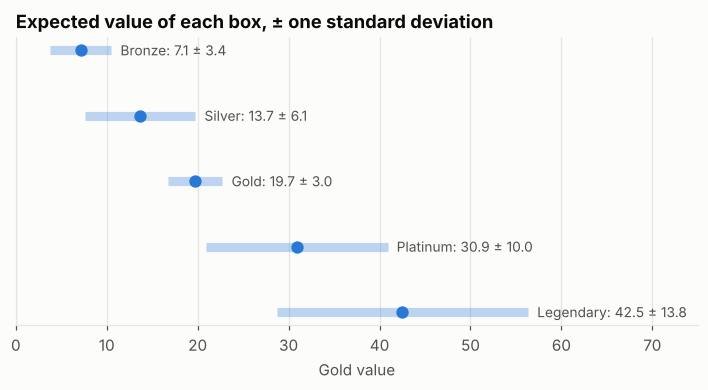

In [3]:
summary = pd.DataFrame([(BOX_TIERS[t]["name"], *box_stats(t)) for t in TIERS],
                       columns=["tier", "ev", "sd"]).set_index("tier")
fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(summary))[::-1]
ax.hlines(y, summary["ev"] - summary["sd"], summary["ev"] + summary["sd"], color=SEQUENTIAL,
          linewidth=6, alpha=0.3)
ax.scatter(summary["ev"], y, color=SEQUENTIAL, s=50, zorder=3)
for yy, (tier, r) in zip(y, summary.iterrows()):
    ax.annotate(f"{tier}: {r['ev']:.1f} ± {r['sd']:.1f}", (r["ev"] + r["sd"], yy), xytext=(6, 0),
                textcoords="offset points", va="center", color=TEXT_2, fontsize=9)
ax.set_yticks([])
ax.set_xlabel("Gold value")
value_grid(ax)
ax.set_xlim(0, 75)
ax.set_title("Expected value of each box, ± one standard deviation")
plt.show()

## 2. Do the boxes really pay out at the stated odds?

The game claims, for example, that a Silver box gives Sponsor Brew 33% of the time. If that's true, the share of Brews across thousands of Silver boxes should be close to 33%, but never exactly.

A **chi-square goodness-of-fit test** asks: *if the stated odds were true, how surprising would counts like these be?*

- The **null hypothesis** is that the stated odds are correct.
- The test statistic adds up $(\text{observed} - \text{expected})^2 / \text{expected}$ over the four items.
- The **p-value** is the chance of a statistic at least that large *if the null is true*. A small p-value (say below 0.05) is evidence the odds are wrong. A large one means the data is consistent with them. It doesn't prove them right.

In [4]:
rows = []
for tier in TIERS:
    got = boxes.loc[boxes["tier"] == tier, "item"].value_counts()
    keys = [k for k, _ in odds(tier)]
    observed = np.array([got.get(k, 0) for k in keys])
    expected = np.array([p for _, p in odds(tier)]) * observed.sum()
    chi2, p = stats.chisquare(observed, expected)
    rows.append(dict(tier=BOX_TIERS[tier]["name"], boxes=observed.sum(), chi2=chi2, p_value=p,
                     verdict="consistent with stated odds" if p >= 0.05 else "odds look wrong"))
pd.DataFrame(rows).style.format({"chi2": "{:.2f}", "p_value": "{:.3f}", "boxes": "{:,}"}).hide(axis="index")

tier,boxes,chi2,p_value,verdict
Bronze,"8,245",0.30,0.961,consistent with stated odds
Silver,"10,224",3.21,0.361,consistent with stated odds
Gold,"6,365",3.45,0.328,consistent with stated odds
Platinum,"1,490",0.63,0.889,consistent with stated odds
Legendary,760,0.61,0.895,consistent with stated odds


**How sensitive is this test?** A test that never rejects anything is useless. To check it can catch a cheat, imagine a dodgy publisher quietly moving 5 percentage points of probability from a Silver box's rarest item to its most common one. How often would the test notice, depending on how many boxes you open? That rate is the test's **power**.

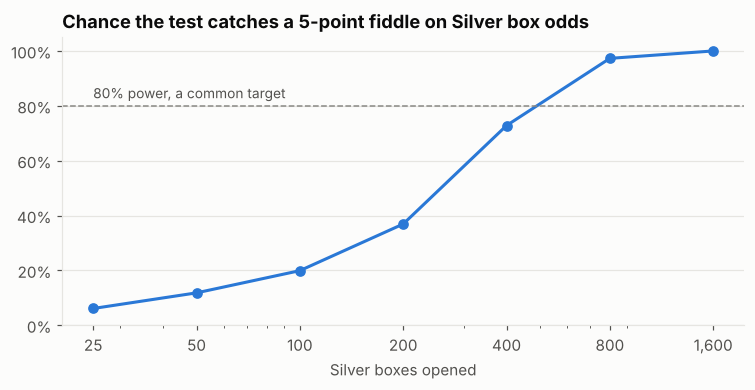

Silver boxes in our data: 10,224


In [5]:
rng = np.random.default_rng(7)
keys = [k for k, _ in odds("silver")]
stated = np.array([p for _, p in odds("silver")])
rigged = stated.copy()
rigged[stated.argmin()] -= 0.05
rigged[stated.argmax()] += 0.05

sizes = [25, 50, 100, 200, 400, 800, 1600]
power = []
for n in sizes:
    hits = 0
    for _ in range(1000):
        counts = rng.multinomial(n, rigged)
        hits += stats.chisquare(counts, stated * n).pvalue < 0.05
    power.append(hits / 1000)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(sizes, power, marker="o", color=SEQUENTIAL)
ax.axhline(0.8, color=MUTED, linewidth=1, linestyle="--")
ax.annotate("80% power, a common target", (sizes[0], 0.8), xytext=(0, 5), textcoords="offset points",
            color=TEXT_2, fontsize=9)
ax.set_xscale("log")
ax.set_xticks(sizes, [f"{n:,}" for n in sizes])
ax.set_ylim(0, 1.05)
pct_axis(ax)
ax.set_xlabel("Silver boxes opened")
ax.set_title("Chance the test catches a 5-point fiddle on Silver box odds")
plt.show()
print(f"Silver boxes in our data: {(boxes['tier'] == 'silver').sum():,}")

With a handful of boxes, one player can't tell a fair box from a fiddled one. It takes hundreds. That's one argument for publishing odds *and* having them audited across the whole player base.

## 3. Luck evens out, but only on average

Each run opens around 15 boxes. Compare what a run actually got (total gold value) with what it should get on average (the sum of each box's EV). The **law of large numbers** says the *average per box* settles towards the EV as you open more boxes. But the *total* gap between luck and average keeps growing, roughly with the square root of the number of boxes.

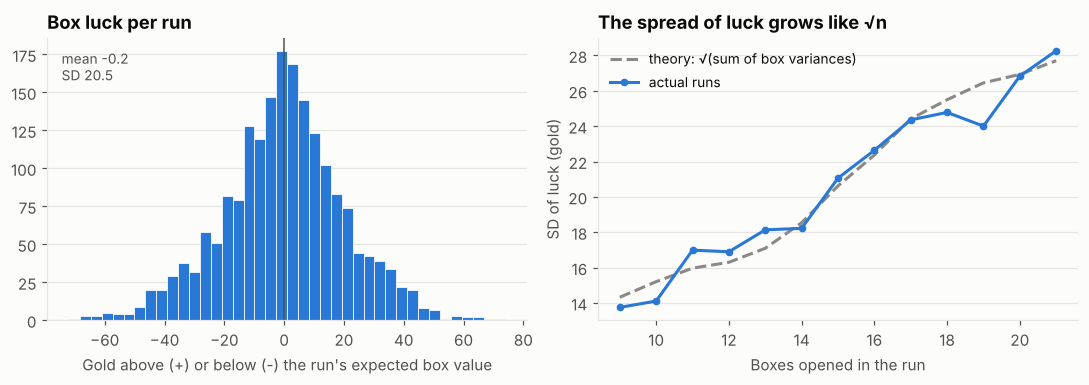

In [6]:
var_by_tier = {t: box_stats(t)[1] ** 2 for t in TIERS}
per_run = boxes.groupby("run_id").agg(n=("value", "size"), got=("value", "sum"), ev=("ev", "sum"),
                                      var=("tier", lambda s: sum(var_by_tier[t] for t in s)))
per_run["luck"] = per_run["got"] - per_run["ev"]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axes[0]
ax.hist(per_run["luck"], bins=40, color=SEQUENTIAL, edgecolor="white", linewidth=0.5)
ax.axvline(0, color=TEXT_2, linewidth=1)
ax.set_xlabel("Gold above (+) or below (-) the run's expected box value")
ax.set_title("Box luck per run")
ax.annotate(f"mean {per_run['luck'].mean():+.1f}\nSD {per_run['luck'].std():.1f}", (0.03, 0.85),
            xycoords="axes fraction", color=TEXT_2, fontsize=9)

ax = axes[1]
binned = per_run.groupby("n").agg(sd_actual=("luck", "std"), sd_theory=("var", lambda v: np.sqrt(v.mean())),
                                  runs=("luck", "size"))
binned = binned[(binned["runs"] >= 30) & (binned.index >= 5)]
ax.plot(binned.index, binned["sd_theory"], color=MUTED, linestyle="--", label="theory: √(sum of box variances)")
ax.plot(binned.index, binned["sd_actual"], color=SEQUENTIAL, marker="o", markersize=4, label="actual runs")
ax.set_xlabel("Boxes opened in the run")
ax.set_ylabel("SD of luck (gold)")
ax.set_title("The spread of luck grows like √n")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

## 4. "It must be due by now": the gambler's fallacy

The rarest item in a Silver box (Half a Trophy, which is junk: rarity isn't the same as value) has a fixed chance on every box. After five Silver boxes without it, many people *feel* the next one is more likely. It isn't. Each box is a fresh, **independent** roll.

Below, we open a million simulated Silver boxes with the game's own `roll_box` and ask: *given you've just missed the rare item k times in a row, what's the chance the next box has it?*

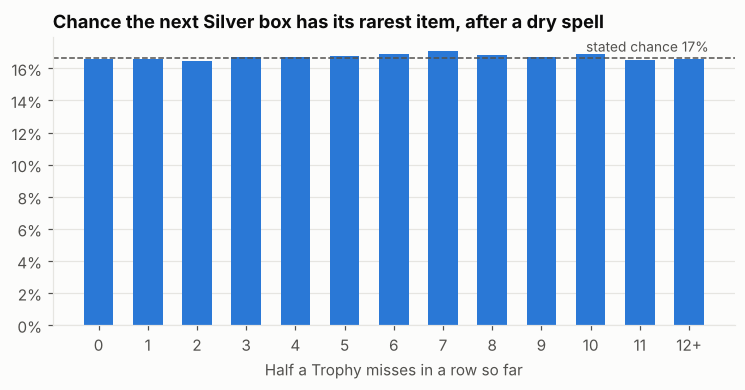

In [7]:
rare, p_rare = min(odds("silver"), key=lambda r: r[1])
rng_game = random.Random(42)
rolls = np.array([roll_box("silver", rng_game) == rare for _ in range(1_000_000)])

streak = 0
hit_after = {}
for r in rolls:
    k = min(streak, 12)
    n, h = hit_after.get(k, (0, 0))
    hit_after[k] = (n + 1, h + r)
    streak = 0 if r else streak + 1
cond = pd.DataFrame([(k, h / n, n) for k, (n, h) in sorted(hit_after.items())],
                    columns=["misses_so_far", "chance_next_is_rare", "times_seen"])

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(cond["misses_so_far"], cond["chance_next_is_rare"], color=SEQUENTIAL, width=0.6)
ax.axhline(p_rare, color=TEXT_2, linewidth=1, linestyle="--")
ax.annotate(f"stated chance {p_rare:.0%}", (12.4, p_rare), xytext=(0, 4), textcoords="offset points",
            ha="right", color=TEXT_2, fontsize=9)
ax.set_xticks(cond["misses_so_far"], [str(k) if k < 12 else "12+" for k in cond["misses_so_far"]])
ax.set_xlabel(f"{ITEMS[rare]['name']} misses in a row so far")
pct_axis(ax)
ax.set_title("Chance the next Silver box has its rarest item, after a dry spell")
plt.show()

The bars are flat: past misses don't change the next box. The *waiting time* until the rare item follows a **geometric distribution**, $P(\text{first success on box } k) = (1-p)^{k-1}p$. Its mean is $1/p$, and long droughts are more common than intuition suggests.

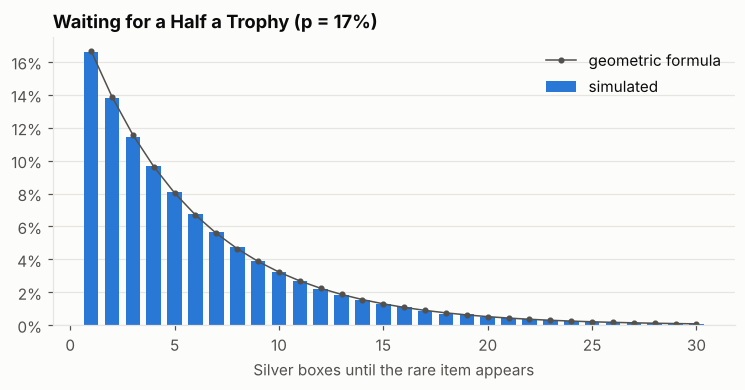

Average wait 6.0 boxes (theory 1/p = 6.0). Waits of 15+ boxes: 7.8% of the time.


In [8]:
waits, gap = [], 0
for r in rolls:
    gap += 1
    if r:
        waits.append(gap)
        gap = 0
waits = np.array(waits)
k = np.arange(1, 31)
geom = (1 - p_rare) ** (k - 1) * p_rare
emp = np.array([(waits == i).mean() for i in k])

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(k, emp, color=SEQUENTIAL, width=0.7, label="simulated")
ax.plot(k, geom, color=TEXT_2, marker="o", markersize=3, linewidth=1, label="geometric formula")
ax.set_xlabel("Silver boxes until the rare item appears")
pct_axis(ax)
ax.legend()
ax.set_title(f"Waiting for a {ITEMS[rare]['name']} (p = {p_rare:.0%})")
plt.show()
print(f"Average wait {waits.mean():.1f} boxes (theory 1/p = {1 / p_rare:.1f}). "
      f"Waits of 15+ boxes: {(waits >= 15).mean():.1%} of the time.")

## 5. Pity timers

Many real games add a **pity timer**: after N misses in a row, the rare item is guaranteed. That caps the worst droughts, but it also means the stated per-box chance is no longer the real chance of getting the item, which becomes *higher* than advertised.

For context: since 22 September 2024, Australian classification guidelines rate games containing paid loot boxes at least M, and games with simulated gambling R 18+.

Here's what a pity timer at different N does to the effective rate and to the drought risk:

In [9]:
def simulate(p, pity, n=400_000, seed=1):
    r = np.random.default_rng(seed).random(n)
    hits, miss, longest_wait, waits, gap = 0, 0, 0, [], 0
    for x in r:
        gap += 1
        if x < p or (pity and miss + 1 >= pity):
            hits += 1
            waits.append(gap)
            miss = gap = 0
        else:
            miss += 1
    waits = np.array(waits)
    return hits / n, waits.mean(), np.percentile(waits, 95)

rows = []
for pity in [None, 15, 10, 6]:
    rate, mean_wait, p95 = simulate(p_rare, pity)
    rows.append(dict(pity_timer="none" if pity is None else f"guaranteed by box {pity}",
                     effective_rate=rate, mean_wait=mean_wait, worst_5pct_wait=p95))
pd.DataFrame(rows).style.format({"effective_rate": "{:.1%}", "mean_wait": "{:.1f}",
                                 "worst_5pct_wait": "{:.0f}"}).hide(axis="index")

pity_timer,effective_rate,mean_wait,worst_5pct_wait
none,16.7%,6.0,17
guaranteed by box 15,17.8%,5.6,15
guaranteed by box 10,19.9%,5.0,10
guaranteed by box 6,25.1%,4.0,6


## 6. Trade-ups and rerolls: the house edge

In a safe room you can trade three boxes of one tier for one of the next tier, or pay a fee to reroll the box you just opened.

- **Trade-up:** you give up three boxes' worth of EV for one box's EV. If what comes back is worth less on average, the difference is the **house edge**.
- **Reroll:** you hand back an item worth $v$ and pay fee $f$ to get a fresh draw worth $E$ on average. It pays on average only if $E - f > v$.

In [10]:
rows = []
for tier in TIERS[:-1]:
    ev_in, _ = box_stats(tier)
    to = next_tier(tier)
    ev_out, sd_out = box_stats(to)
    rows.append(dict(trade=f"{TRADE_UP_COST} {BOX_TIERS[tier]['name']} → 1 {BOX_TIERS[to]['name']}",
                     value_in=TRADE_UP_COST * ev_in, value_out=ev_out,
                     house_edge=1 - ev_out / (TRADE_UP_COST * ev_in), sd_out=sd_out))
pd.DataFrame(rows).style.format({"value_in": "{:.1f}", "value_out": "{:.1f}", "house_edge": "{:.0%}",
                                 "sd_out": "{:.1f}"}).hide(axis="index")

trade,value_in,value_out,house_edge,sd_out
3 Bronze → 1 Silver,21.4,13.7,36%,6.1
3 Silver → 1 Gold,41.0,19.7,52%,3.0
3 Gold → 1 Platinum,59.2,30.9,48%,10.0
3 Platinum → 1 Legendary,92.7,42.5,54%,13.8


In [11]:
rows = []
for tier in TIERS:
    ev, _ = box_stats(tier)
    fee = reroll_fee(tier)
    worth = [ITEMS[k]["name"] for k, _ in odds(tier) if ITEMS[k]["value"] < ev - fee]
    rows.append(dict(tier=BOX_TIERS[tier]["name"], ev=ev, fee=fee, reroll_if_worth_under=ev - fee,
                     reroll_these=", ".join(worth) or "nothing"))
pd.DataFrame(rows).style.format({"ev": "{:.1f}", "reroll_if_worth_under": "{:.1f}"}).hide(axis="index")

tier,ev,fee,reroll_if_worth_under,reroll_these
Bronze,7.1,2,5.1,Soggy Sock
Silver,13.7,4,9.7,Half a Trophy
Gold,19.7,6,13.7,nothing
Platinum,30.9,9,21.9,Crate of Fireworks
Legendary,42.5,13,29.5,Crate of Fireworks


**Takeaways**

- The boxes pay out at their stated odds. Thousands of openings can't tell them apart from the table, and the power check shows the test would catch a real fiddle at this sample size.
- Your total luck drifts further from the average the more boxes you open, even though your *average* per box gets closer. Both are true at once.
- Dry spells don't make a win more likely. Only a pity timer does that, and it quietly changes the real odds.
- Every trade-up loses value on average: the house edge. It's only worth it if you want something only the bigger box contains.